<a href="https://colab.research.google.com/github/aycaaozturk/AML-project/blob/main/Step_3_Plausability_Check_for_Twins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

RANDOM_STATE = 42

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
BASE_DIR = Path(
    "/content/drive/MyDrive/Uniklinikum Würzburg/AML/"
    "Output Files 2/combined_survival_model_ready_wout_protocol/"
)

TRAIN_PATH = BASE_DIR / "combined_train_survival_model_ready.csv"
TEST_PATH = BASE_DIR / "combined_test_survival_model_ready.csv"

DIGITAL_TWIN_DIR = BASE_DIR / "digital_twins"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (620, 68)
Test: (89, 68)


In [3]:
NON_FEATURE_COLS = [
    "PATIENT_ID",
    "SAMPLE_ID",
    "OS_DAYS",
    "OS_EVENT"
]

FEATURE_COLS = [
    col for col in train_df.columns
    if col not in NON_FEATURE_COLS
]

X_train = train_df[FEATURE_COLS].copy()
X_test = test_df[FEATURE_COLS].copy()

CF_FEATURES = [
    "WBC_LOG1P",
    "PERIPHERAL_BLASTS_PERCENTAGE",
    "BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE"
]

CF_FEATURES = [
    f for f in CF_FEATURES
    if f in FEATURE_COLS
]

print("Counterfactual features:")
for f in CF_FEATURES:
    print("-", f)

Counterfactual features:
- WBC_LOG1P
- PERIPHERAL_BLASTS_PERCENTAGE
- BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE


In [4]:
CF_TARGETS = {
    feature: X_train[feature].median()
    for feature in CF_FEATURES
}

print("\nCounterfactual target values:")

for feature, value in CF_TARGETS.items():
    print(feature, "→", round(value, 4))


Counterfactual target values:
WBC_LOG1P → -0.0399
PERIPHERAL_BLASTS_PERCENTAGE → 0.0509
BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE → 0.243


In [5]:
X_cf = X_test.copy()

for feature, target in CF_TARGETS.items():

    mask = X_cf[feature] > target

    X_cf.loc[
        mask,
        feature
    ] = target


print("Baseline test shape:", X_test.shape)
print("Counterfactual shape:", X_cf.shape)

Baseline test shape: (89, 64)
Counterfactual shape: (89, 64)


In [6]:
change_summary = []

for feature in CF_FEATURES:

    changed = (
        X_test[feature] !=
        X_cf[feature]
    )

    change_summary.append({
        "Feature": feature,
        "N_Changed": changed.sum(),
        "Pct_Changed": changed.mean() * 100,
        "Mean_Original":
            X_test[feature].mean(),
        "Mean_Counterfactual":
            X_cf[feature].mean()
    })

change_summary_df = pd.DataFrame(
    change_summary
)

display(
    change_summary_df.round(4)
)

,Feature,N_Changed,Pct_Changed,Mean_Original,Mean_Counterfactual
0,WBC_LOG1P,45,50.5618,-0.0501,-0.4993
1,PERIPHERAL_BLASTS_PERCENTAGE,33,37.0787,-0.1627,-0.5047
2,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,38,42.6966,-0.0405,-0.3085


In [7]:
range_rows = []

for feature in CF_FEATURES:

    x = X_train[feature].dropna()

    range_rows.append({
        "Feature": feature,

        "Train_Min": x.min(),
        "Q01": x.quantile(0.01),
        "Q05": x.quantile(0.05),
        "Q10": x.quantile(0.10),
        "Q25": x.quantile(0.25),
        "Median": x.median(),
        "Q75": x.quantile(0.75),
        "Q90": x.quantile(0.90),
        "Q95": x.quantile(0.95),
        "Q99": x.quantile(0.99),
        "Train_Max": x.max()
    })

plausible_ranges = pd.DataFrame(
    range_rows
)

display(
    plausible_ranges.round(4)
)

,Feature,Train_Min,Q01,Q05,Q10,Q25,Median,Q75,Q90,Q95,Q99,Train_Max
0,WBC_LOG1P,-2.5336,-2.0225,-1.6506,-1.3006,-0.7551,-0.0399,0.7585,1.3664,1.5997,1.9766,2.2463
1,PERIPHERAL_BLASTS_PERCENTAGE,-1.4471,-1.4471,-1.4471,-1.4189,-0.9452,0.0509,0.9058,1.3450,1.4705,1.6274,1.6587
2,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,-2.6787,-2.5318,-1.8145,-1.4861,-0.7035,0.2430,0.8452,1.1097,1.2307,1.3708,1.4364


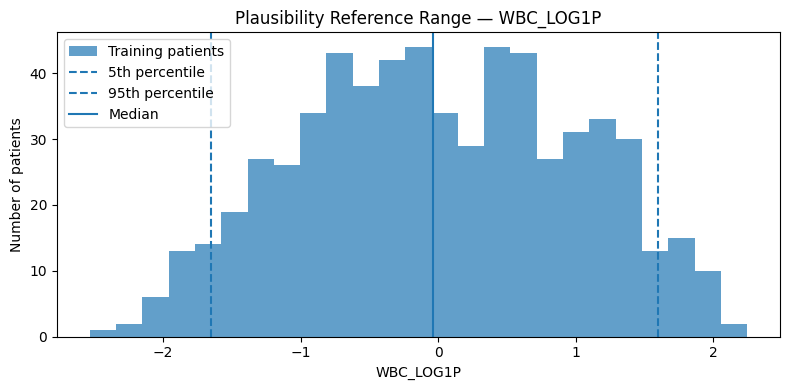

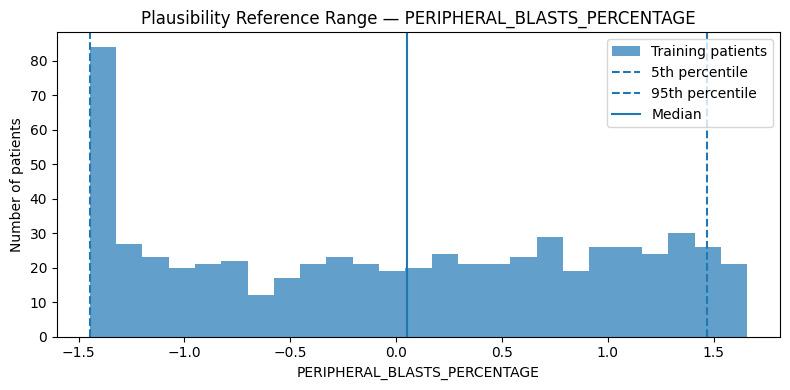

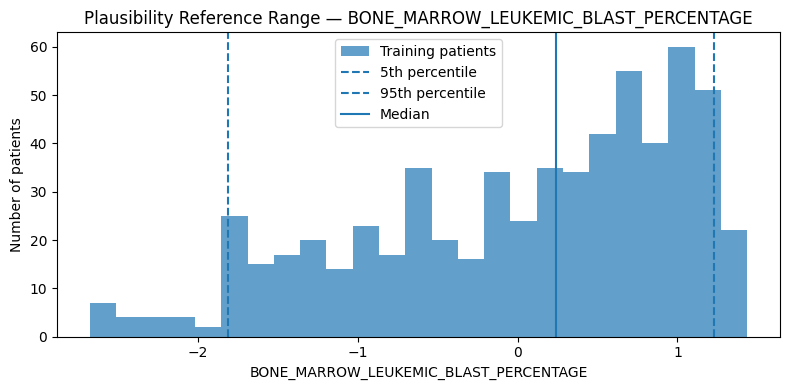

In [8]:
for feature in CF_FEATURES:

    plt.figure(figsize=(8, 4))

    plt.hist(
        X_train[feature].dropna(),
        bins=25,
        alpha=0.7,
        label="Training patients"
    )

    plt.axvline(
        X_train[feature].quantile(0.05),
        linestyle="--",
        label="5th percentile"
    )

    plt.axvline(
        X_train[feature].quantile(0.95),
        linestyle="--",
        label="95th percentile"
    )

    plt.axvline(
        X_train[feature].median(),
        linestyle="-",
        label="Median"
    )

    plt.xlabel(feature)
    plt.ylabel("Number of patients")

    plt.title(
        f"Plausibility Reference Range — {feature}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

In [9]:
range_check = pd.DataFrame({
    "PATIENT_ID":
        test_df["PATIENT_ID"].values
})

for feature in CF_FEATURES:

    train_min = X_train[feature].min()
    train_max = X_train[feature].max()

    q01 = X_train[feature].quantile(0.01)
    q99 = X_train[feature].quantile(0.99)

    values = X_cf[feature]

    range_check[
        f"{feature}_Inside_MinMax"
    ] = (
        (values >= train_min)
        &
        (values <= train_max)
    )

    range_check[
        f"{feature}_Inside_Q01_Q99"
    ] = (
        (values >= q01)
        &
        (values <= q99)
    )

In [10]:
minmax_cols = [
    c for c in range_check.columns
    if c.endswith("_Inside_MinMax")
]

quantile_cols = [
    c for c in range_check.columns
    if c.endswith("_Inside_Q01_Q99")
]

range_check[
    "PASS_HARD_RANGE"
] = range_check[
    minmax_cols
].all(axis=1)

range_check[
    "PASS_Q01_Q99"
] = range_check[
    quantile_cols
].all(axis=1)

display(
    range_check.head(10)
)

,PATIENT_ID,WBC_LOG1P_Inside_MinMax,WBC_LOG1P_Inside_Q01_Q99,PERIPHERAL_BLASTS_PERCENTAGE_Inside_MinMax,PERIPHERAL_BLASTS_PERCENTAGE_Inside_Q01_Q99,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE_Inside_MinMax,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE_Inside_Q01_Q99,PASS_HARD_RANGE,PASS_Q01_Q99
0,TARGET-21-PANVPB,True,True,True,True,True,True,True,True
1,TARGET-20-PASHZX,True,True,True,True,True,True,True,True
2,TARGET-20-PASKFN,True,True,True,True,True,True,True,True
3,TARGET-20-PATAST,True,True,True,True,True,True,True,True
4,TARGET-20-PASYRE,True,True,True,True,True,True,True,True
5,TARGET-20-PARHJV,True,True,True,True,True,True,True,True
6,TARGET-20-PAKLPD,True,True,True,True,True,True,True,True
7,TARGET-20-PARSRR,True,True,True,True,True,True,True,True
8,TARGET-20-PATMCW,True,True,True,True,True,True,True,True
9,TARGET-20-PATEMK,True,True,True,True,True,True,True,True


In [11]:
print(
    "Twins inside training min/max:",
    range_check["PASS_HARD_RANGE"].mean() * 100,
    "%"
)

print(
    "Twins inside Q01–Q99:",
    range_check["PASS_Q01_Q99"].mean() * 100,
    "%"
)

Twins inside training min/max: 100.0 %
Twins inside Q01–Q99: 96.62921348314607 %


In [12]:
knn_scaler = StandardScaler()

train_knn = knn_scaler.fit_transform(
    X_train[CF_FEATURES]
)

cf_knn = knn_scaler.transform(
    X_cf[CF_FEATURES]
)

baseline_knn = knn_scaler.transform(
    X_test[CF_FEATURES]
)

print(train_knn.shape)
print(cf_knn.shape)

(620, 3)
(89, 3)


In [13]:
K = 5

knn = NearestNeighbors(
    n_neighbors=K
)

knn.fit(
    train_knn
)

NearestNeighbors()

In [14]:
train_neighbor_model = NearestNeighbors(
    n_neighbors=K + 1
)

train_neighbor_model.fit(
    train_knn
)

train_distances, _ = (
    train_neighbor_model.kneighbors(
        train_knn
    )
)

# Ignore self-distance = 0
train_mean_knn_distance = (
    train_distances[:, 1:]
    .mean(axis=1)
)

print(
    "Median training KNN distance:",
    round(
        np.median(
            train_mean_knn_distance
        ),
        4
    )
)

Median training KNN distance: 0.2976


In [15]:
KNN_THRESHOLD = np.quantile(
    train_mean_knn_distance,
    0.95
)

print(
    "95th percentile KNN threshold:",
    round(KNN_THRESHOLD, 4)
)

95th percentile KNN threshold: 0.5228


In [16]:
baseline_distances, _ = knn.kneighbors(
    baseline_knn
)

cf_distances, cf_neighbor_indices = (
    knn.kneighbors(
        cf_knn
    )
)

baseline_mean_distance = (
    baseline_distances.mean(axis=1)
)

cf_mean_distance = (
    cf_distances.mean(axis=1)
)

In [17]:
knn_results = pd.DataFrame({
    "PATIENT_ID":
        test_df["PATIENT_ID"].values,

    "Baseline_KNN_Distance":
        baseline_mean_distance,

    "Counterfactual_KNN_Distance":
        cf_mean_distance
})

knn_results[
    "Distance_Change"
] = (
    knn_results[
        "Counterfactual_KNN_Distance"
    ]
    -
    knn_results[
        "Baseline_KNN_Distance"
    ]
)

knn_results[
    "KNN_Plausible"
] = (
    knn_results[
        "Counterfactual_KNN_Distance"
    ]
    <=
    KNN_THRESHOLD
)

display(
    knn_results
    .sort_values(
        "Counterfactual_KNN_Distance",
        ascending=False
    )
    .head(15)
    .round(4)
)

,PATIENT_ID,Baseline_KNN_Distance,Counterfactual_KNN_Distance,Distance_Change,KNN_Plausible
62,TARGET-20-PATBRA,0.6127,0.6007,-0.0120,False
58,TARGET-20-PATDIC,0.5630,0.5630,0.0000,False
28,TARGET-20-PASHWV,0.5602,0.5451,-0.0151,False
1,TARGET-20-PASHZX,0.4494,0.4494,0.0000,True
10,TARGET-20-PATESX,0.4406,0.4406,0.0000,True
71,TARGET-20-PATGRP,0.4546,0.4339,-0.0207,True
37,TARGET-20-PARZIA,0.3811,0.4263,0.0452,True
21,TARGET-20-PARDEV,0.4320,0.4104,-0.0216,True
18,TARGET-21-PARLSL,0.2781,0.4082,0.1300,True
66,TARGET-20-PARFWM,0.4034,0.4022,-0.0012,True


In [18]:
n_total = len(knn_results)

n_plausible = (
    knn_results[
        "KNN_Plausible"
    ].sum()
)

n_implausible = (
    (~knn_results[
        "KNN_Plausible"
    ]).sum()
)

print("Total counterfactual twins:", n_total)
print("Plausible:", n_plausible)
print("Implausible:", n_implausible)

print(
    "Plausible percentage:",
    round(
        100 * n_plausible / n_total,
        2
    ),
    "%"
)

Total counterfactual twins: 89
Plausible: 86
Implausible: 3
Plausible percentage: 96.63 %


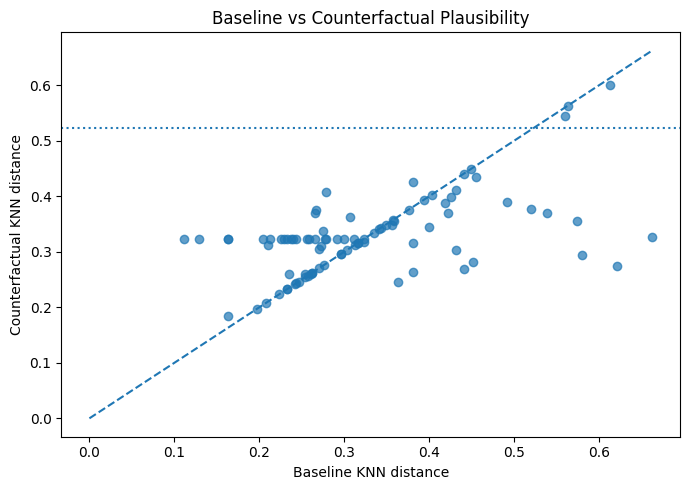

In [19]:
plt.figure(figsize=(7, 5))

plt.scatter(
    knn_results[
        "Baseline_KNN_Distance"
    ],
    knn_results[
        "Counterfactual_KNN_Distance"
    ],
    alpha=0.7
)

max_value = max(
    knn_results[
        "Baseline_KNN_Distance"
    ].max(),
    knn_results[
        "Counterfactual_KNN_Distance"
    ].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.axhline(
    KNN_THRESHOLD,
    linestyle=":"
)

plt.xlabel(
    "Baseline KNN distance"
)

plt.ylabel(
    "Counterfactual KNN distance"
)

plt.title(
    "Baseline vs Counterfactual Plausibility"
)

plt.tight_layout()
plt.show()

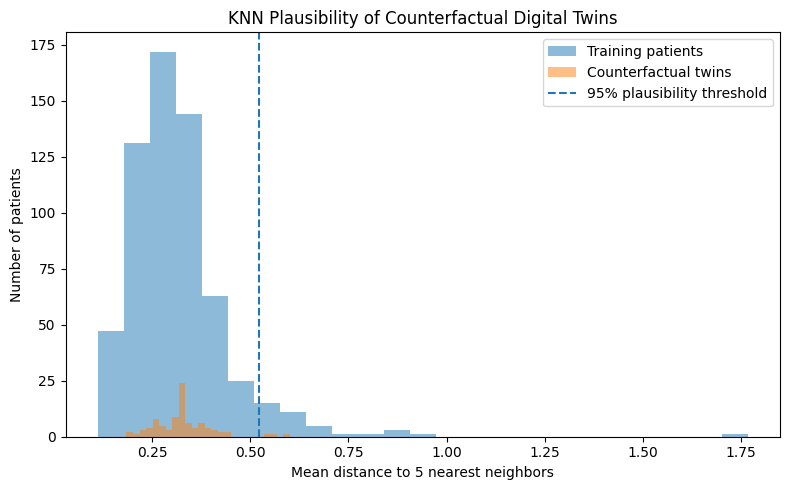

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(
    train_mean_knn_distance,
    bins=25,
    alpha=0.5,
    label="Training patients"
)

plt.hist(
    cf_mean_distance,
    bins=25,
    alpha=0.5,
    label="Counterfactual twins"
)

plt.axvline(
    KNN_THRESHOLD,
    linestyle="--",
    label="95% plausibility threshold"
)

plt.xlabel(
    "Mean distance to 5 nearest neighbors"
)

plt.ylabel(
    "Number of patients"
)

plt.title(
    "KNN Plausibility of Counterfactual Digital Twins"
)

plt.legend()
plt.tight_layout()
plt.show()

In [21]:
worst_twins = (
    knn_results
    .sort_values(
        "Counterfactual_KNN_Distance",
        ascending=False
    )
    .head(10)
)

display(
    worst_twins.round(4)
)

,PATIENT_ID,Baseline_KNN_Distance,Counterfactual_KNN_Distance,Distance_Change,KNN_Plausible
62,TARGET-20-PATBRA,0.6127,0.6007,-0.0120,False
58,TARGET-20-PATDIC,0.5630,0.5630,0.0000,False
28,TARGET-20-PASHWV,0.5602,0.5451,-0.0151,False
1,TARGET-20-PASHZX,0.4494,0.4494,0.0000,True
10,TARGET-20-PATESX,0.4406,0.4406,0.0000,True
71,TARGET-20-PATGRP,0.4546,0.4339,-0.0207,True
37,TARGET-20-PARZIA,0.3811,0.4263,0.0452,True
21,TARGET-20-PARDEV,0.4320,0.4104,-0.0216,True
18,TARGET-21-PARLSL,0.2781,0.4082,0.1300,True
66,TARGET-20-PARFWM,0.4034,0.4022,-0.0012,True


In [22]:
worst_indices = (
    worst_twins.index
)

worst_feature_values = (
    X_cf.loc[
        worst_indices,
        CF_FEATURES
    ]
    .copy()
)

worst_feature_values.insert(
    0,
    "PATIENT_ID",
    test_df.loc[
        worst_indices,
        "PATIENT_ID"
    ].values
)

display(
    worst_feature_values.round(4)
)

,PATIENT_ID,WBC_LOG1P,PERIPHERAL_BLASTS_PERCENTAGE,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE
62,TARGET-20-PATBRA,-2.3624,-1.4158,0.2430
58,TARGET-20-PATDIC,-1.6297,-0.5373,-0.8269
28,TARGET-20-PASHWV,-2.3130,-1.3216,0.2430
1,TARGET-20-PASHZX,-1.3944,-0.1295,-0.0639
10,TARGET-20-PATESX,-0.2994,-0.3177,-1.6911
71,TARGET-20-PATGRP,-0.0399,0.0509,-1.2796
37,TARGET-20-PARZIA,-1.7349,-0.2421,0.2430
21,TARGET-20-PARDEV,-2.1044,-1.2275,0.2430
18,TARGET-21-PARLSL,-0.0753,-1.4471,0.2430
66,TARGET-20-PARFWM,-0.0399,-0.9138,-0.0450


In [23]:
PATIENT_INDEX = (
    knn_results[
        "Counterfactual_KNN_Distance"
    ]
    .idxmax()
)

patient_id = (
    test_df.loc[
        PATIENT_INDEX,
        "PATIENT_ID"
    ]
)

print(
    "Most unusual counterfactual:",
    patient_id
)

Most unusual counterfactual: TARGET-20-PATBRA


In [24]:
query = cf_knn[
    PATIENT_INDEX
].reshape(1, -1)

distances, indices = (
    knn.kneighbors(query)
)

nearest_real_patients = (
    train_df.iloc[
        indices[0]
    ][
        ["PATIENT_ID"] +
        CF_FEATURES
    ]
    .copy()
)

nearest_real_patients[
    "KNN_Distance"
] = distances[0]

print(
    "Counterfactual twin:"
)

display(
    X_cf.loc[
        [PATIENT_INDEX],
        CF_FEATURES
    ].round(4)
)

print(
    "Nearest real training patients:"
)

display(
    nearest_real_patients.round(4)
)

Counterfactual twin:


,WBC_LOG1P,PERIPHERAL_BLASTS_PERCENTAGE,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE
62,-2.3624,-1.4158,0.243


Nearest real training patients:


,PATIENT_ID,WBC_LOG1P,PERIPHERAL_BLASTS_PERCENTAGE,BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE,KNN_Distance
243,TARGET-20-PASMTK,-2.2665,-1.1334,-0.0450,0.4146
138,TARGET-20-PARBCV,-1.8057,-1.3216,0.4488,0.6009
602,TARGET-20-PARPDS,-1.8057,-1.1648,0.2019,0.6121
458,TARGET-20-PASSNX,-1.7349,-1.4471,0.0784,0.6495
447,TARGET-20-PASWPD,-1.8309,-1.3216,-0.2428,0.7263


In [25]:
change_matrix = (
    X_cf[CF_FEATURES]
    -
    X_test[CF_FEATURES]
)

absolute_change_matrix = (
    change_matrix.abs()
)

change_magnitude = (
    np.sqrt(
        (
            change_matrix ** 2
        ).sum(axis=1)
    )
)

change_results = pd.DataFrame({
    "PATIENT_ID":
        test_df["PATIENT_ID"].values,

    "Change_Magnitude":
        change_magnitude
})

for feature in CF_FEATURES:

    change_results[
        f"Delta_{feature}"
    ] = (
        change_matrix[
            feature
        ].values
    )

display(
    change_results
    .sort_values(
        "Change_Magnitude",
        ascending=False
    )
    .head(10)
    .round(4)
)

,PATIENT_ID,Change_Magnitude,Delta_WBC_LOG1P,Delta_PERIPHERAL_BLASTS_PERCENTAGE,Delta_BONE_MARROW_LEUKEMIC_BLAST_PERCENTAGE
24,TARGET-20-PARSXZ,2.6880,-2.1728,-1.4196,-0.6995
51,TARGET-20-PAKKIM,2.6818,-1.8837,-1.6078,-1.0288
29,TARGET-20-PATGIG,2.4748,-1.8913,-1.5137,-0.5062
44,TARGET-21-PASFHK,2.3432,-1.8405,-1.1059,-0.9382
49,TARGET-21-PASFJJ,2.0442,-1.0513,-1.4196,-1.0288
73,TARGET-20-PASICM,2.0268,-1.7435,-0.7608,-0.6996
80,TARGET-20-PATESK,2.0214,-1.9632,-0.4813,0.0000
48,TARGET-20-PAEEYP,2.0020,-1.2868,-1.2941,-0.8230
31,TARGET-20-PARDPM,1.9180,-1.2238,-1.2314,-0.8153
63,TARGET-21-PAMYMA,1.8538,-1.5631,-0.6667,-0.7407


In [26]:
plausibility_results = (
    knn_results
    .merge(
        range_check[
            [
                "PATIENT_ID",
                "PASS_HARD_RANGE",
                "PASS_Q01_Q99"
            ]
        ],
        on="PATIENT_ID"
    )
)

plausibility_results[
    "FINAL_PLAUSIBLE"
] = (
    plausibility_results[
        "PASS_HARD_RANGE"
    ]
    &
    plausibility_results[
        "PASS_Q01_Q99"
    ]
    &
    plausibility_results[
        "KNN_Plausible"
    ]
)

display(
    plausibility_results
    .head(20)
    .round(4)
)

,PATIENT_ID,Baseline_KNN_Distance,Counterfactual_KNN_Distance,Distance_Change,KNN_Plausible,PASS_HARD_RANGE,PASS_Q01_Q99,FINAL_PLAUSIBLE
0,TARGET-21-PANVPB,0.2123,0.3226,0.1103,True,True,True,True
1,TARGET-20-PASHZX,0.4494,0.4494,0.0000,True,True,True,True
2,TARGET-20-PASKFN,0.3229,0.3229,0.0000,True,True,True,True
3,TARGET-20-PATAST,0.2999,0.3226,0.0226,True,True,True,True
4,TARGET-20-PASYRE,0.4320,0.3038,-0.1281,True,True,True,True
5,TARGET-20-PARHJV,0.4510,0.2816,-0.1695,True,True,True,True
6,TARGET-20-PAKLPD,0.2590,0.3226,0.0635,True,True,True,True
7,TARGET-20-PARSRR,0.2233,0.2233,0.0000,True,True,True,True
8,TARGET-20-PATMCW,0.3805,0.2635,-0.1169,True,True,True,True
9,TARGET-20-PATEMK,0.4002,0.3443,-0.0559,True,True,True,True


In [27]:
summary = pd.DataFrame({

    "Criterion": [
        "Inside training min/max",
        "Inside Q01-Q99",
        "KNN plausible",
        "Final plausible"
    ],

    "N_Pass": [
        plausibility_results[
            "PASS_HARD_RANGE"
        ].sum(),

        plausibility_results[
            "PASS_Q01_Q99"
        ].sum(),

        plausibility_results[
            "KNN_Plausible"
        ].sum(),

        plausibility_results[
            "FINAL_PLAUSIBLE"
        ].sum()
    ]
})

summary[
    "Percent_Pass"
] = (
    summary[
        "N_Pass"
    ]
    /
    len(
        plausibility_results
    )
    *
    100
)

display(
    summary.round(2)
)

,Criterion,N_Pass,Percent_Pass
0,Inside training min/max,89,100.00
1,Inside Q01-Q99,86,96.63
2,KNN plausible,86,96.63
3,Final plausible,85,95.51


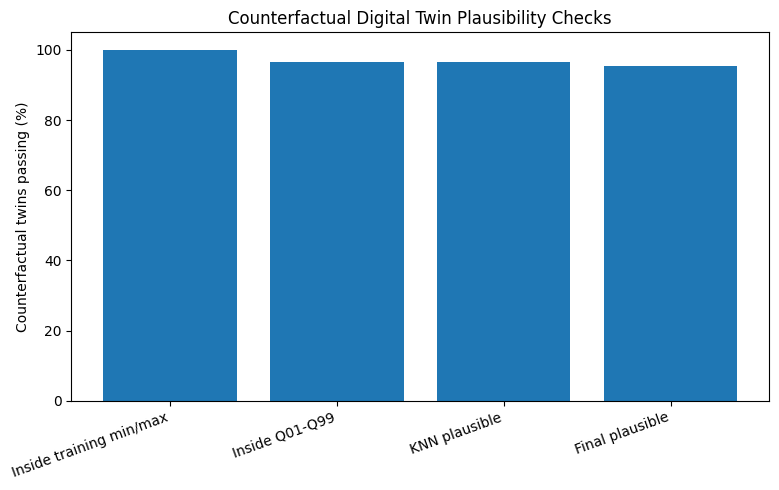

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Criterion"],
    summary["Percent_Pass"]
)

plt.ylabel(
    "Counterfactual twins passing (%)"
)

plt.ylim(
    0,
    105
)

plt.title(
    "Counterfactual Digital Twin Plausibility Checks"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()
plt.show()

In [29]:
accepted_indices = (
    plausibility_results[
        "FINAL_PLAUSIBLE"
    ].values
)

X_cf_accepted = (
    X_cf.loc[
        accepted_indices
    ].copy()
)

X_cf_rejected = (
    X_cf.loc[
        ~accepted_indices
    ].copy()
)

print(
    "Accepted twins:",
    len(X_cf_accepted)
)

print(
    "Rejected / flagged twins:",
    len(X_cf_rejected)
)

Accepted twins: 85
Rejected / flagged twins: 4


In [30]:
PLAUSIBILITY_DIR = (
    DIGITAL_TWIN_DIR /
    "plausibility_analysis"
)

PLAUSIBILITY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

plausibility_results.to_csv(
    PLAUSIBILITY_DIR /
    "counterfactual_plausibility_results.csv",
    index=False
)

plausible_ranges.to_csv(
    PLAUSIBILITY_DIR /
    "counterfactual_plausible_ranges.csv",
    index=False
)

knn_results.to_csv(
    PLAUSIBILITY_DIR /
    "counterfactual_knn_results.csv",
    index=False
)

summary.to_csv(
    PLAUSIBILITY_DIR /
    "counterfactual_plausibility_summary.csv",
    index=False
)

X_cf_accepted.to_csv(
    PLAUSIBILITY_DIR /
    "plausible_counterfactual_twins.csv",
    index=False
)

X_cf_rejected.to_csv(
    PLAUSIBILITY_DIR /
    "flagged_counterfactual_twins.csv",
    index=False
)

print(
    "✓ Plausibility analysis saved to:",
    PLAUSIBILITY_DIR
)

✓ Plausibility analysis saved to: /content/drive/MyDrive/Uniklinikum Würzburg/AML/Output Files 2/combined_survival_model_ready_wout_protocol/digital_twins/plausibility_analysis
